# Explore House Sales Data

This notebook reads the cleaned dataset from `Cleaned_Datasets/` and uses simple summaries and plots to understand house prices and features.

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

In [10]:
data = pd.read_csv("Cleaned_Datasets/house_sales_clean.csv")
print(f"Rows and columns: {data.shape}")
print(f"Missing values: {data.isna().sum().sum()}")
display(data.head())
display(data[["price", "sqft_living", "bedrooms", "bathrooms"]].describe().round(1))

Rows and columns: (21613, 20)
Missing values: 0


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,zipcode,lat,long,sqft_living15,sqft_lot15,house_age,sale_month,renovated
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,98178,47.5112,-122.257,1340,5650,59,10,0
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,98125,47.7210,-122.319,1690,7639,63,12,1
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,98028,47.7379,-122.233,2720,8062,82,2,0
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,98136,47.5208,-122.393,1360,5000,49,12,0
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,98074,47.6168,-122.045,1800,7503,28,2,0


,price,sqft_living,bedrooms,bathrooms
count,21613.0,21613.0,21613.0,21613.0
mean,540088.1,2079.9,3.4,2.1
std,367127.2,918.4,0.9,0.8
min,75000.0,290.0,0.0,0.0
25%,321950.0,1427.0,3.0,1.8
50%,450000.0,1910.0,3.0,2.2
75%,645000.0,2550.0,4.0,2.5
max,7700000.0,13540.0,33.0,8.0


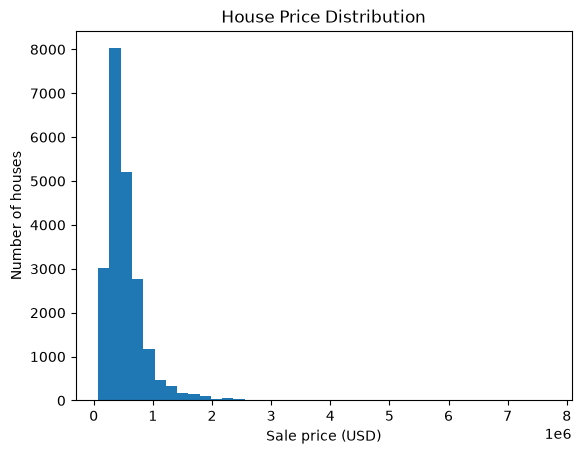

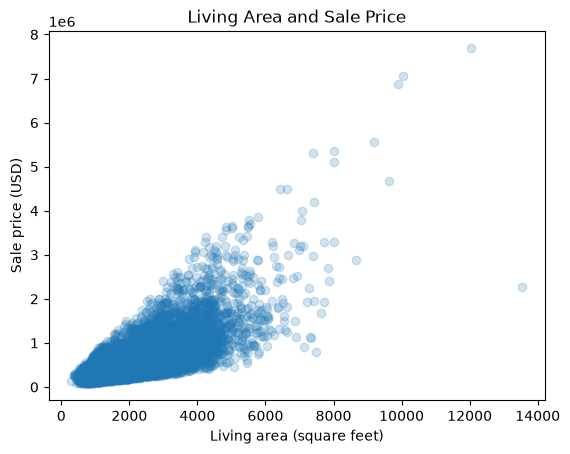

In [11]:
plt.hist(data["price"], bins=40)
plt.xlabel("Sale price (USD)")
plt.ylabel("Number of houses")
plt.title("House Price Distribution")
plt.show()

plt.scatter(data["sqft_living"], data["price"], alpha=0.2)
plt.xlabel("Living area (square feet)")
plt.ylabel("Sale price (USD)")
plt.title("Living Area and Sale Price")
plt.show()

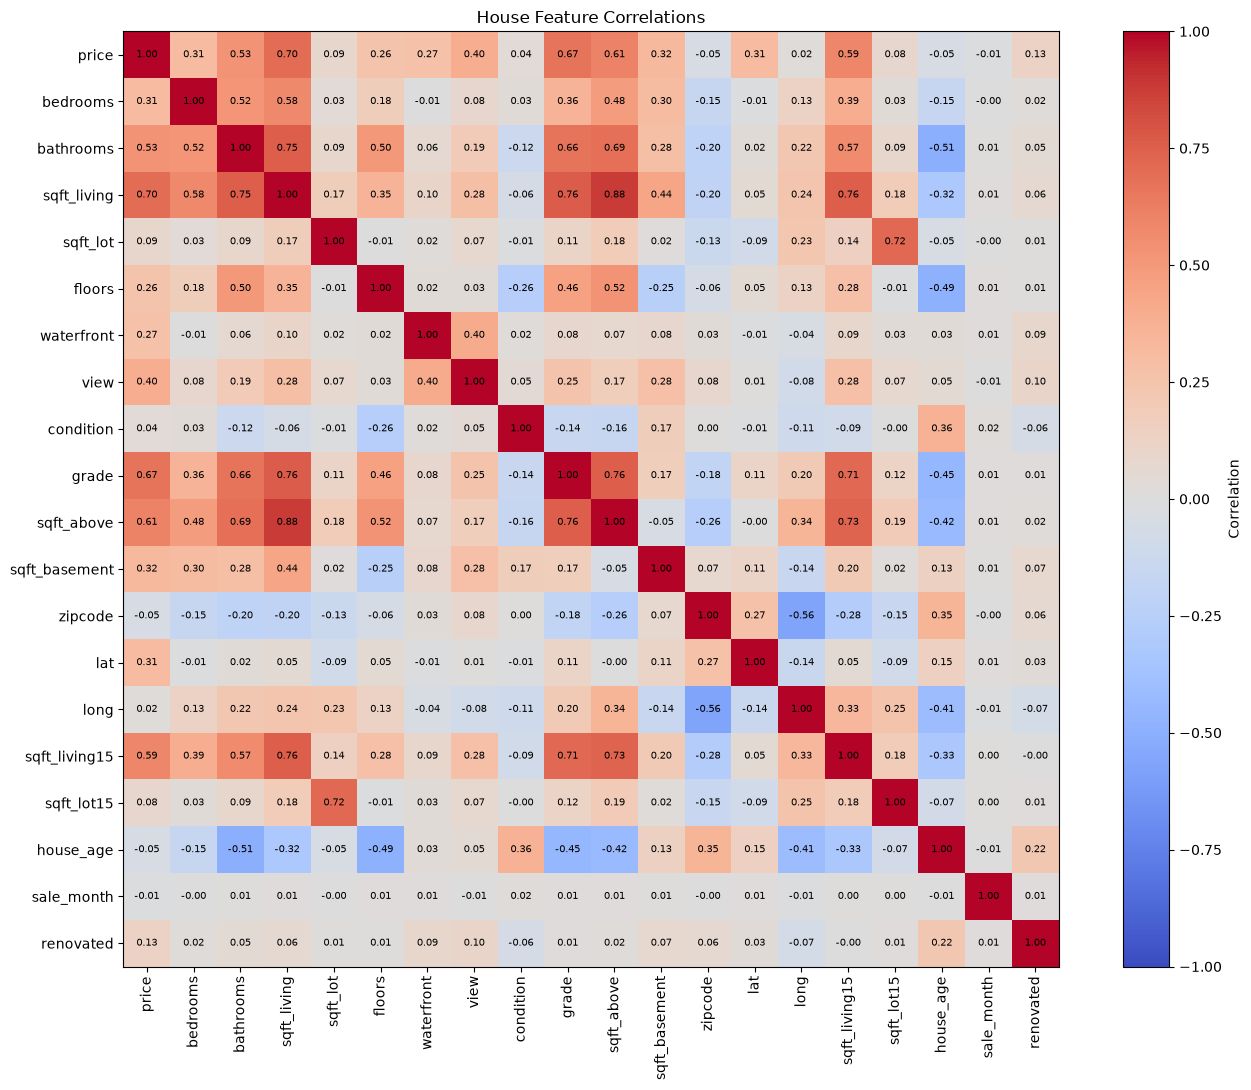

In [12]:
correlation = data.corr(numeric_only=True)
plt.figure(figsize=(14, 11))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

for row in range(len(correlation)):
    for column in range(len(correlation.columns)):
        plt.text(
            column,
            row,
            f"{correlation.iloc[row, column]:.2f}",
            ha="center",
            va="center",
            fontsize=7,
        )

plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.title("House Feature Correlations")
plt.tight_layout()
plt.show()